<a href="https://colab.research.google.com/github/ayuannisa17/PCdVK_ganjil_2026/blob/main/week5_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Ayu Annisa Aryani Nagari'
NIM = '244107020185'
N = int(NIM[-3:])

PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L' : 2 ** ((N % 3) + 1),
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA :', NAMA)
print('NIM :', NIM, '| N =', N)

for k, v in PARAM.items():
    print('%-6s :' % k, v)

print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))


NAMA : Ayu Annisa Aryani Nagari
NIM : 244107020185 | N = 185
bins   : 16
clip   : 1.0
tile   : 3
L      : 8
WAKTU : 2026-09-30 17:34:46 WIB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
## Import library

import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io

import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

## E-1 PERCOBAAN HISTOGRAM

<BarContainer object of 256 artists>

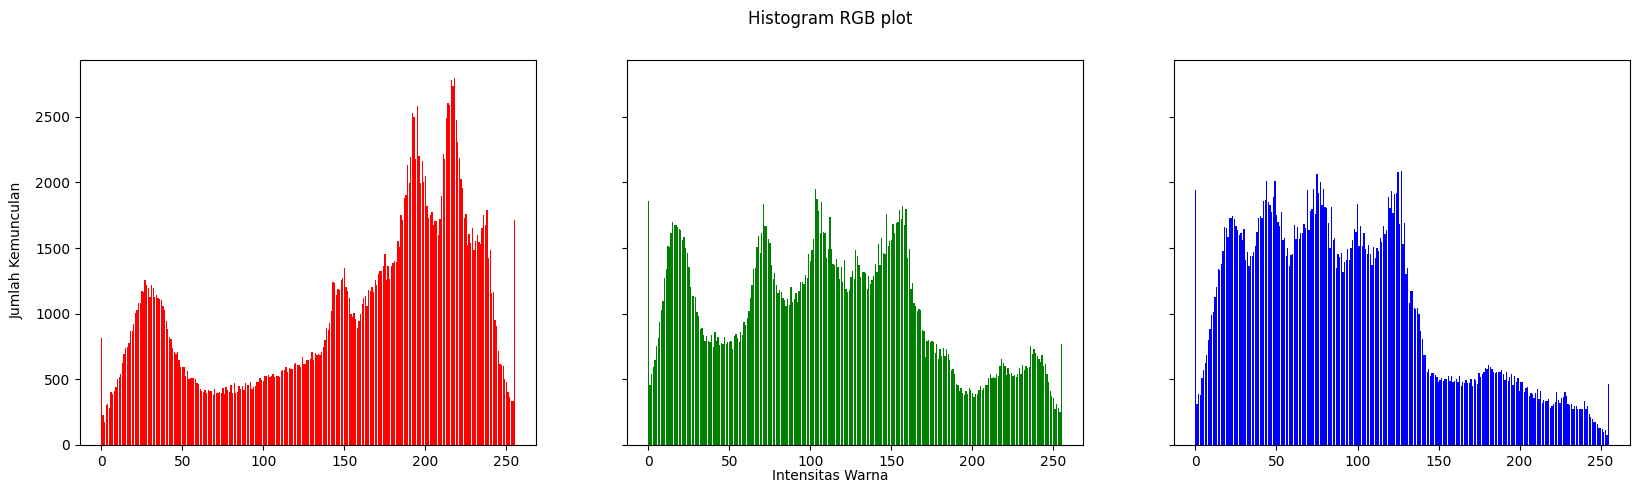

In [ ]:
#membuat histogram image (manual)
img = cv.imread('/content/drive/MyDrive/PCdVK/lenna.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0,height) :
    for x in range(0,width) :
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=(20,5), sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

## PERTANYAAN PRAKTIKUM E1


# 1. Buatlah histogram citra yang sama menggunakan library NumPy, yaitu numpy.histogram, dan juga cv.calcHist. Bandingkan ketiganya dengan menghitung selisih maksimum antar hasil. Selisihnya harus nol; tampilkan pembuktiannya pada lena.jpg lebih dulu, kemudian ulangi pada KTM1b.jpg.

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def bandingkan_histogram(path):
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)

    if img is None:
        print(f"Gambar tidak ditemukan: {path}")
        return

    # Histogram manual
    hist_manual = [0] * 256

    height, width = img.shape

    for y in range(height):
        for x in range(width):
            hist_manual[img[y, x]] += 1

    hist_manual = np.array(hist_manual)

    # Histogram menggunakan NumPy
    hist_numpy, bins = np.histogram(img.ravel(), bins=256, range=(0, 256))

    # Histogram menggunakan OpenCV
    hist_cv = cv.calcHist([img], [0], None, [256], [0, 256])
    hist_cv = hist_cv.flatten().astype(int)

    # Menghitung selisih maksimum
    selisih_manual_numpy = np.max(np.abs(hist_manual - hist_numpy))
    selisih_manual_cv = np.max(np.abs(hist_manual - hist_cv))
    selisih_numpy_cv = np.max(np.abs(hist_numpy - hist_cv))

    print(f"Hasil perbandingan: {path}")
    print("Selisih manual dan NumPy :", selisih_manual_numpy)
    print("Selisih manual dan OpenCV:", selisih_manual_cv)
    print("Selisih NumPy dan OpenCV :", selisih_numpy_cv)

    # Menampilkan histogram
    plt.figure(figsize=(12, 5))
    plt.plot(hist_manual, label='Manual')
    plt.plot(hist_numpy, '--', label='NumPy')
    plt.plot(hist_cv, ':', label='OpenCV')
    plt.title(f'Perbandingan Histogram - {path.split("/")[-1]}')
    plt.xlabel('Intensitas Piksel')
    plt.ylabel('Jumlah Piksel')
    plt.legend()
    plt.grid()
    plt.show()

Hasil perbandingan: /content/drive/MyDrive/PCdVK/lenna.jpg
Selisih manual dan NumPy : 0
Selisih manual dan OpenCV: 0
Selisih NumPy dan OpenCV : 0


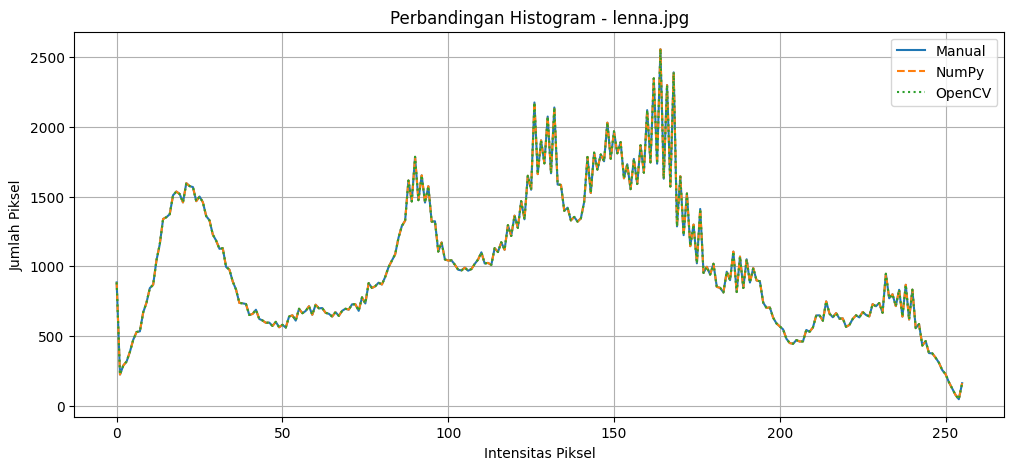

In [ ]:
bandingkan_histogram('/content/drive/MyDrive/PCdVK/lenna.jpg')

Hasil perbandingan: /content/drive/MyDrive/PCdVK/KTM.jpg
Selisih manual dan NumPy : 0
Selisih manual dan OpenCV: 0
Selisih NumPy dan OpenCV : 0


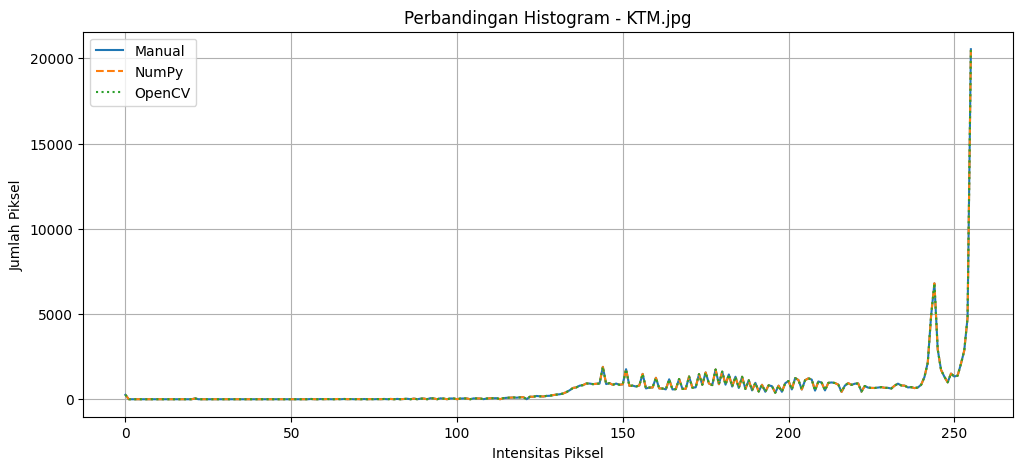

In [ ]:
bandingkan_histogram('/content/drive/MyDrive/PCdVK/KTM.jpg')

# 2. Gambarkan histogram ternormalisasi p(j) dan kurva CDF untuk KTM1a.jpg sampai KTM1d.jpg dalam satu figure 2 x 2. Jelaskan perbedaan bentuk kurva CDF antara citra paling gelap dan citra paling terang milik Anda, lalu kaitkan dengan kondisi pencahayaan saat akuisisi pada Pertemuan 2.

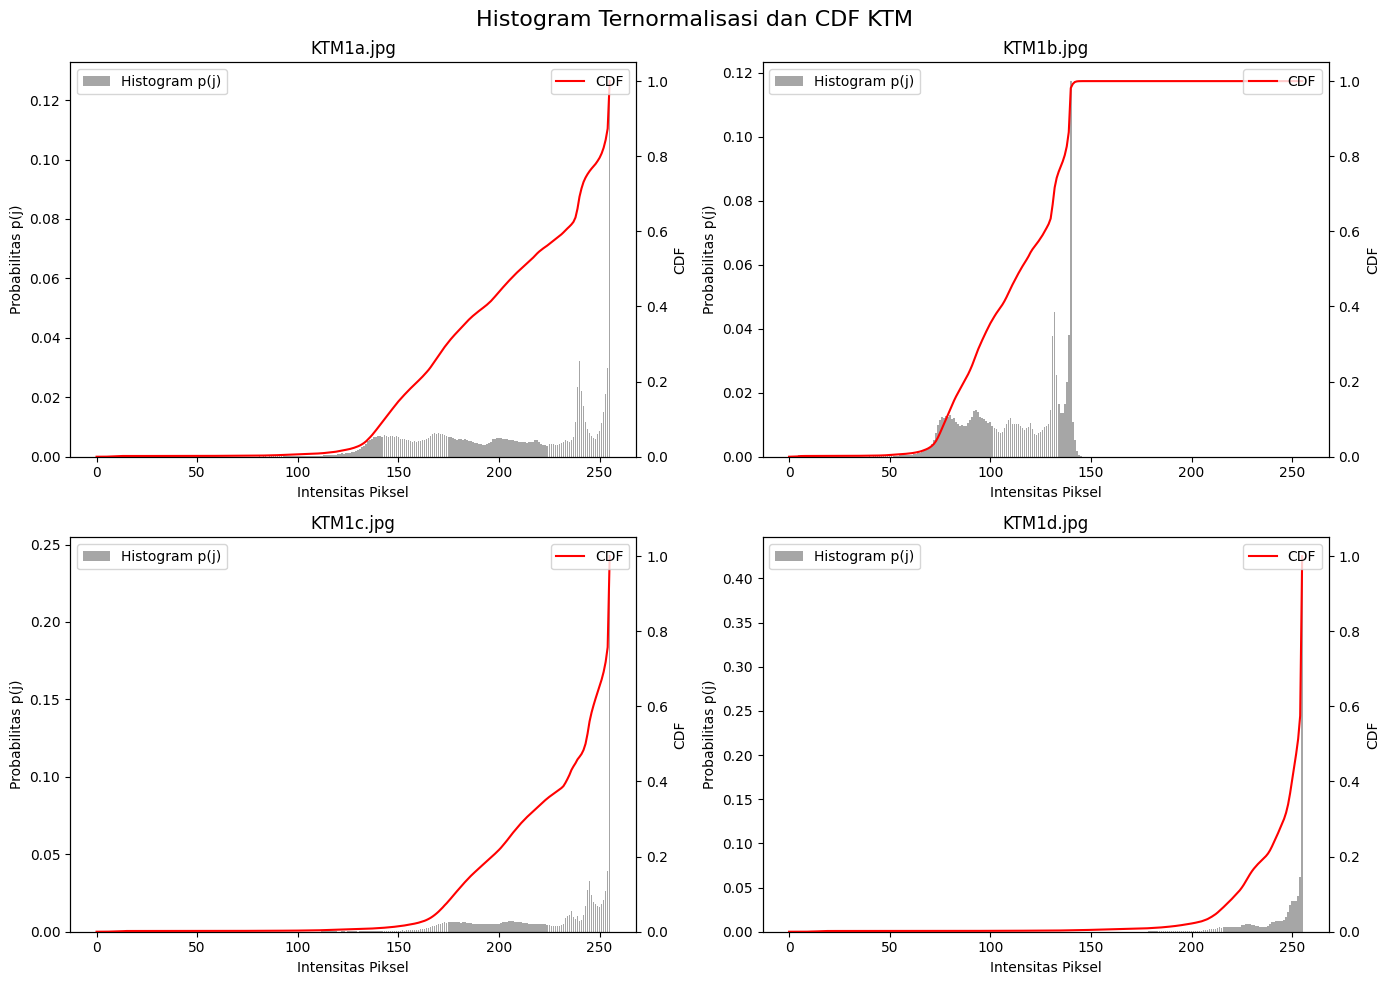

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

files = ['KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg']

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Histogram Ternormalisasi dan CDF KTM', fontsize=16)

for i, file in enumerate(files):
    img = cv.imread('/content/drive/MyDrive/PCdVK/' + file, cv.IMREAD_GRAYSCALE)

    if img is None:
        print(f'Gambar tidak ditemukan: {file}')
        continue

    # Histogram 256 bin
    hist = cv.calcHist([img], [0], None, [256], [0, 256]).flatten()

    # Histogram ternormalisasi
    p = hist / hist.sum()

    # Cumulative Distribution Function
    cdf = np.cumsum(p)

    ax = axs[i // 2, i % 2]

    # Histogram ternormalisasi
    ax.bar(range(256), p, color='gray', alpha=0.7, label='Histogram p(j)')
    ax.set_xlabel('Intensitas Piksel')
    ax.set_ylabel('Probabilitas p(j)')
    ax.set_title(file)

    # Kurva CDF pada sumbu kedua
    ax2 = ax.twinx()
    ax2.plot(range(256), cdf, color='red', label='CDF')
    ax2.set_ylabel('CDF')
    ax2.set_ylim(0, 1.05)

    ax.legend(loc='upper left')
    ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# 3. Ulangi histogram KTM1b.jpg dengan jumlah bin sebesar PARAM['bins'] dan dengan 256 bin. Tampilkan keduanya berdampingan dan jelaskan informasi apa yang hilang ketika jumlah bin dikurangi.

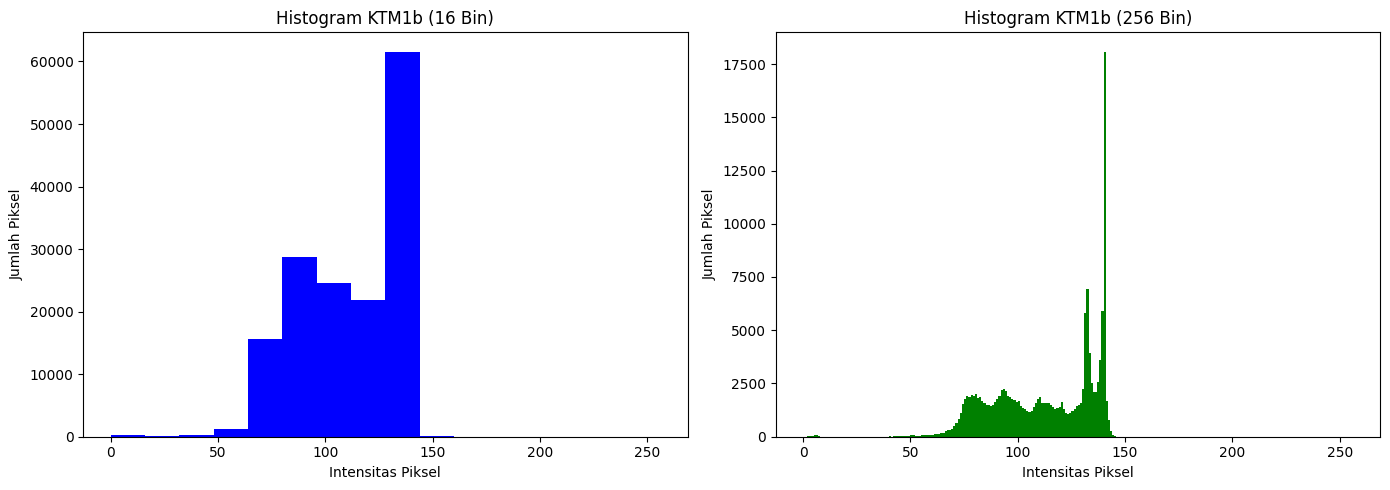

In [ ]:
# Membaca citra KTM1b
img = cv.imread('/content/drive/MyDrive/PCdVK/KTM1b.jpg', cv.IMREAD_GRAYSCALE)

# Histogram dengan jumlah bin sesuai PARAM
hist_param, bins_param = np.histogram(
    img.ravel(),
    bins=PARAM['bins'],
    range=(0, 256)
)

# Histogram dengan 256 bin
hist_256, bins_256 = np.histogram(
    img.ravel(),
    bins=256,
    range=(0, 256)
)

# Menampilkan histogram berdampingan
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Histogram PARAM['bins']
axs[0].bar(
    bins_param[:-1],
    hist_param,
    width=np.diff(bins_param),
    color='blue',
    align='edge'
)
axs[0].set_title(f'Histogram KTM1b ({PARAM["bins"]} Bin)')
axs[0].set_xlabel('Intensitas Piksel')
axs[0].set_ylabel('Jumlah Piksel')

# Histogram 256 bin
axs[1].bar(
    bins_256[:-1],
    hist_256,
    width=np.diff(bins_256),
    color='green',
    align='edge'
)
axs[1].set_title('Histogram KTM1b (256 Bin)')
axs[1].set_xlabel('Intensitas Piksel')
axs[1].set_ylabel('Jumlah Piksel')

plt.tight_layout()
plt.show()

## E-2 PERCOBAAN HISTOGRAM EQUALIZATION

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


False


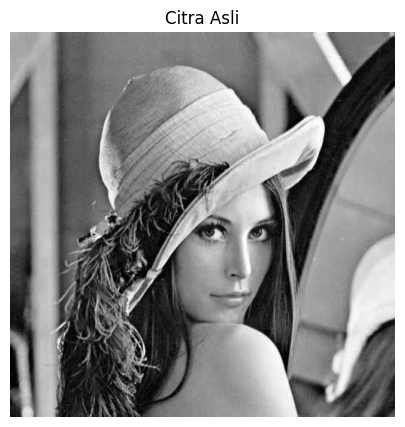

In [9]:
# E-2.1 - Membaca citra

img = cv.imread(
    '/content/drive/MyDrive/PCdVK/lenna.jpg',
    cv.IMREAD_GRAYSCALE
)

print(img is None)

plt.figure(figsize=(6, 5))
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')
plt.show()

In [10]:
# Menghitung histogram
hist = np.bincount(img.ravel(), minlength=256)

# Menghitung frekuensi kumulatif
cdf = hist.cumsum()

# Normalisasi frekuensi kumulatif
cdf_normalized = cdf / cdf[-1]

# Transformasi intensitas
transform = np.round(cdf_normalized * 255).astype(np.uint8)

# Menghasilkan citra histogram equalization
img_eq = transform[img]

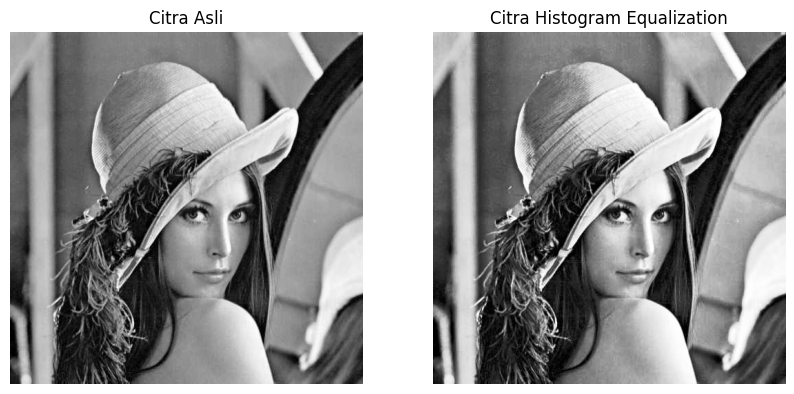

In [11]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_eq, cmap='gray')
plt.title('Citra Histogram Equalization')
plt.axis('off')

plt.show()

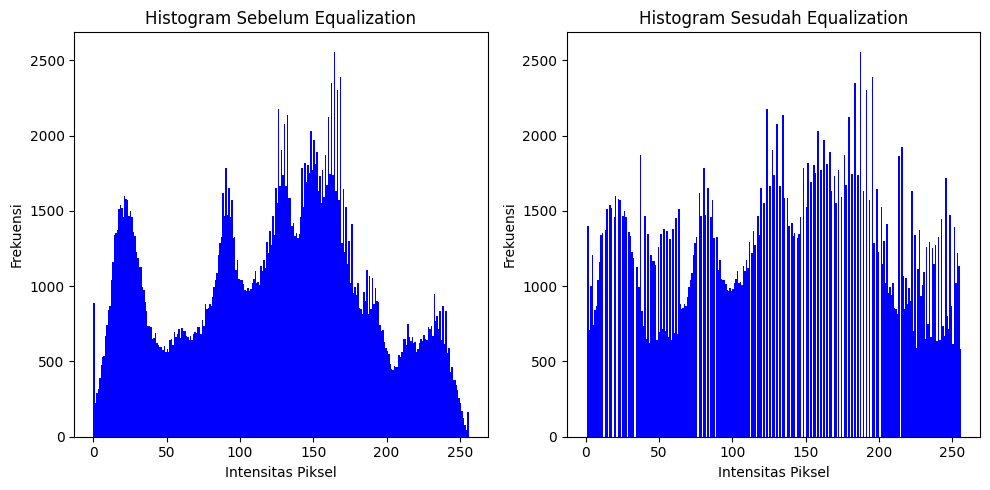

In [13]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.hist(img.ravel(), bins=256, range=(0, 256), color='blue')
plt.title('Histogram Sebelum Equalization')
plt.xlabel('Intensitas Piksel')
plt.ylabel('Frekuensi')

plt.subplot(1, 2, 2)
plt.hist(img_eq.ravel(), bins=256, range=(0, 256), color='blue')
plt.title('Histogram Sesudah Equalization')
plt.xlabel('Intensitas Piksel')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [14]:
img_ktm = cv.imread('/content/drive/MyDrive/PCdVK/KTM1a.jpg', cv.IMREAD_GRAYSCALE)

if img_ktm is None:
    print("Citra tidak ditemukan!")
else:
    print("Citra berhasil dimuat.")

Citra berhasil dimuat.


In [15]:
hist_ktm = np.bincount(img_ktm.ravel(), minlength=256)
cdf_ktm = hist_ktm.cumsum()

cdf_normalized_ktm = cdf_ktm / cdf_ktm[-1]
transform_ktm = np.round(cdf_normalized_ktm * 255).astype(np.uint8)

img_ktm_eq = transform_ktm[img_ktm]

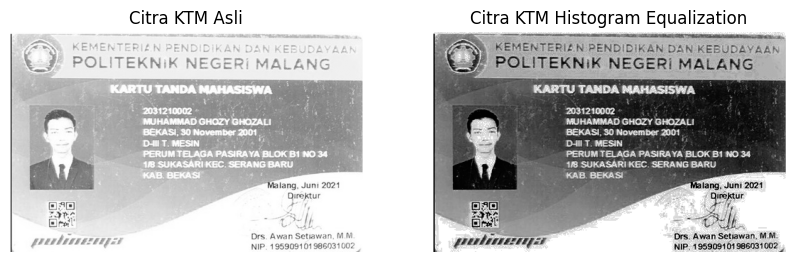

In [16]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_ktm, cmap='gray')
plt.title('Citra KTM Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_ktm_eq, cmap='gray')
plt.title('Citra KTM Histogram Equalization')
plt.axis('off')

plt.show()

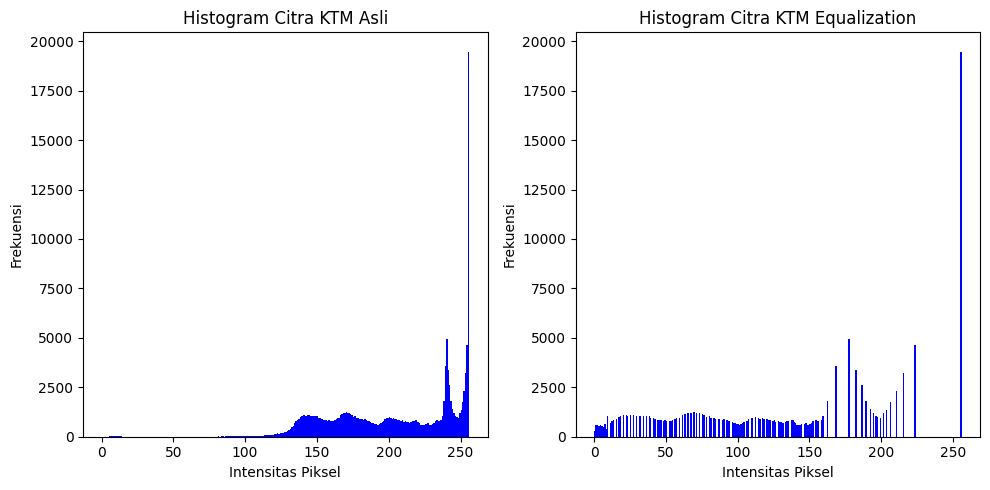

In [17]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.hist(img_ktm.ravel(), bins=256, range=[0, 256], color='blue')
plt.title('Histogram Citra KTM Asli')
plt.xlabel('Intensitas Piksel')
plt.ylabel('Frekuensi')

plt.subplot(1, 2, 2)
plt.hist(img_ktm_eq.ravel(), bins=256, range=[0, 256], color='blue')
plt.title('Histogram Citra KTM Equalization')
plt.xlabel('Intensitas Piksel')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

## 2.


In [18]:
# Fungsi equalization menggunakan OpenCV
def equalize_opencv(img):
    b, g, r = cv.split(img)

    b_equalized = cv.equalizeHist(b)
    g_equalized = cv.equalizeHist(g)
    r_equalized = cv.equalizeHist(r)

    return cv.merge((b_equalized, g_equalized, r_equalized))


# Fungsi equalization manual
def equalize_manual(img):
    b, g, r = cv.split(img)

    def manual_channel(channel):
        hist = np.bincount(channel.ravel(), minlength=256)
        cdf = hist.cumsum()
        cdf_normalized = cdf / cdf[-1]
        transform = np.round(cdf_normalized * 255).astype(np.uint8)
        return transform[channel]

    b_eq = manual_channel(b)
    g_eq = manual_channel(g)
    r_eq = manual_channel(r)

    return cv.merge((b_eq, g_eq, r_eq))

Selisih maksimum Lenna: 2


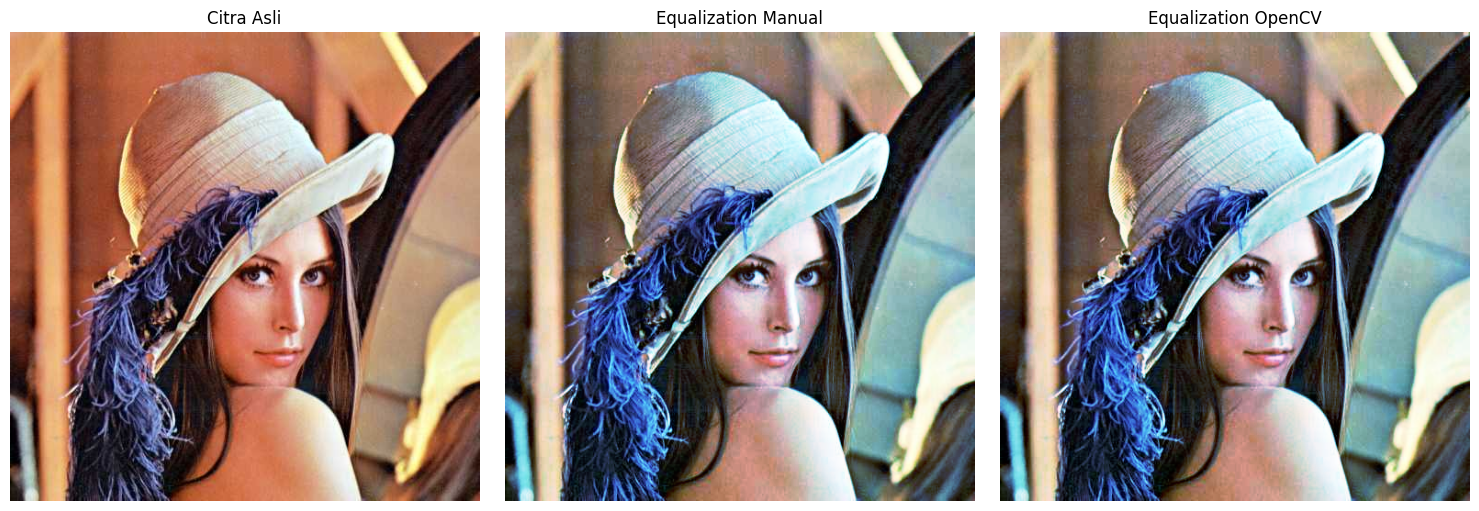

In [19]:
img_lenna = cv.imread('/content/drive/MyDrive/PCdVK/lenna.jpg')

# Equalization
lenna_manual = equalize_manual(img_lenna)
lenna_cv2 = equalize_opencv(img_lenna)

# Menghitung selisih maksimum
diff_lenna = cv.absdiff(lenna_manual, lenna_cv2)
max_diff_lenna = np.max(diff_lenna)

print("Selisih maksimum Lenna:", max_diff_lenna)

# Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img_lenna, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(lenna_manual, cv.COLOR_BGR2RGB))
plt.title('Equalization Manual')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(lenna_cv2, cv.COLOR_BGR2RGB))
plt.title('Equalization OpenCV')
plt.axis('off')

plt.tight_layout()
plt.show()

Selisih maksimum KTM1a: 1


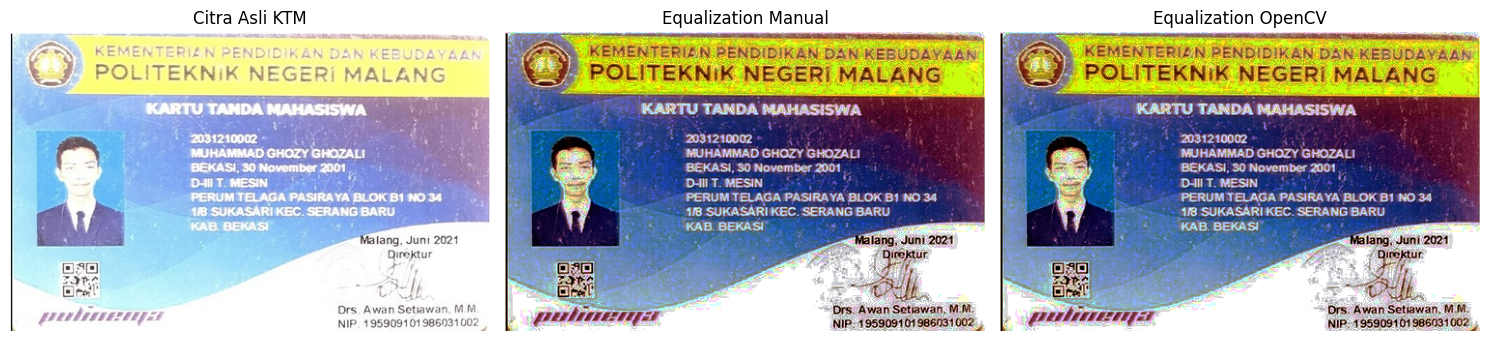

In [20]:
img_ktm_color = cv.imread('/content/drive/MyDrive/PCdVK/KTM1a.jpg')

# Equalization
ktm_manual = equalize_manual(img_ktm_color)
ktm_cv2 = equalize_opencv(img_ktm_color)

# Menghitung selisih maksimum
diff_ktm = cv.absdiff(ktm_manual, ktm_cv2)
max_diff_ktm = np.max(diff_ktm)

print("Selisih maksimum KTM1a:", max_diff_ktm)

# Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img_ktm_color, cv.COLOR_BGR2RGB))
plt.title('Citra Asli KTM')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(ktm_manual, cv.COLOR_BGR2RGB))
plt.title('Equalization Manual')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(ktm_cv2, cv.COLOR_BGR2RGB))
plt.title('Equalization OpenCV')
plt.axis('off')

plt.tight_layout()
plt.show()

In [21]:
print("Hasil Perbandingan Histogram Equalization")
print("Lenna  :", max_diff_lenna)
print("KTM1a  :", max_diff_ktm)

Hasil Perbandingan Histogram Equalization
Lenna  : 2
KTM1a  : 1


## 3.

Ukuran citra: (310, 497, 3)


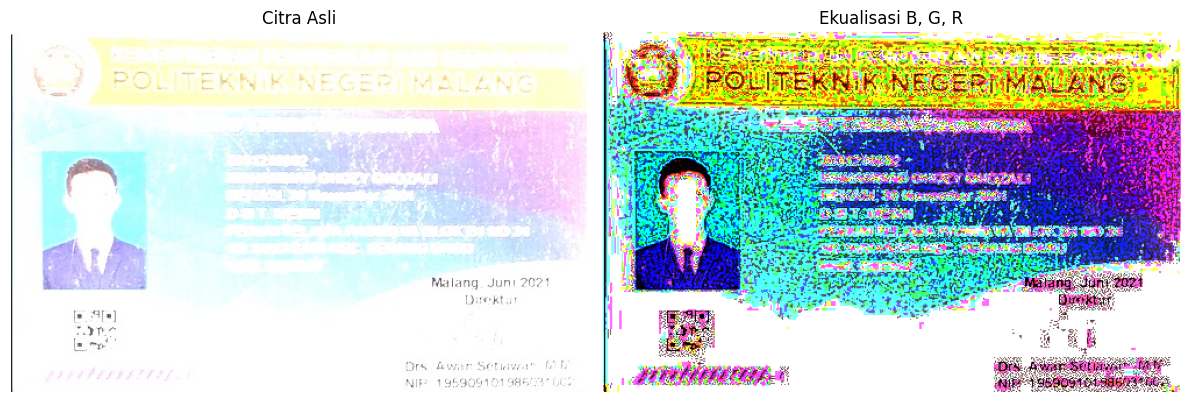

In [38]:
berkas = '/content/drive/MyDrive/PCdVK/KTM1d.jpg'

# Membaca citra dalam format berwarna
bgr = cv.imread(berkas, cv.IMREAD_COLOR)

if bgr is None:
    print("Gambar tidak ditemukan. Periksa lokasi dan nama file!")
else:
    print("Ukuran citra:", bgr.shape)

    # Cara 1: tiap kanal diekualisasi sendiri-sendiri
    kanal = list(cv.split(bgr))

    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])

    he_rgb = cv.merge(kanal)

    # Menampilkan hasil
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
    plt.title('Citra Asli')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(he_rgb, cv.COLOR_BGR2RGB))
    plt.title('Ekualisasi B, G, R')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

## 4.

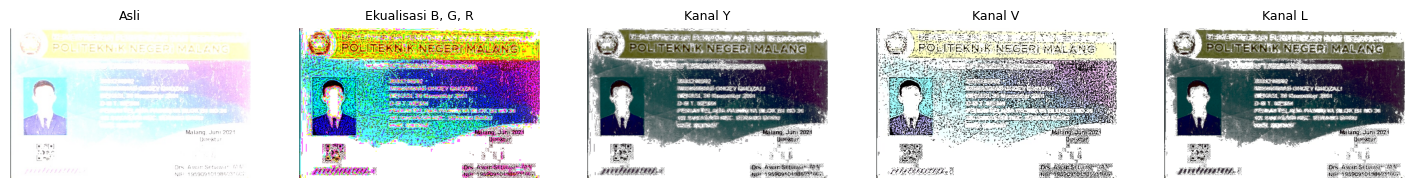

In [40]:
# Cara 2: hanya kanal terang yang diekualisasi

ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
y, cr, cb = cv.split(ycrcb)

he_y = cv.cvtColor(
    cv.merge([cv.equalizeHist(y), cr, cb]),
    cv.COLOR_YCrCb2BGR
)


# Varian pada ruang warna lain

hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
h, sat, v = cv.split(hsv)

he_v = cv.cvtColor(
    cv.merge([h, sat, cv.equalizeHist(v)]),
    cv.COLOR_HSV2BGR
)


lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
l, a, b = cv.split(lab)

he_l = cv.cvtColor(
    cv.merge([cv.equalizeHist(l), a, b]),
    cv.COLOR_LAB2BGR
)
judul = [
    'Asli',
    'Ekualisasi B, G, R',
    'Kanal Y',
    'Kanal V',
    'Kanal L'
]

citra = [
    bgr,
    he_rgb,
    he_y,
    he_v,
    he_l
]

plt.figure(figsize=(18, 4))

for i, (c, t) in enumerate(zip(citra, judul), 1):
    plt.subplot(1, 5, i)
    plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
    plt.title(t, fontsize=9)
    plt.axis('off')

plt.show()

In [31]:
def geser_hue(asli, hasil):
    h1 = cv.cvtColor(
        asli,
        cv.COLOR_BGR2HSV
    )[:, :, 0].astype(np.int16)

    h2 = cv.cvtColor(
        hasil,
        cv.COLOR_BGR2HSV
    )[:, :, 0].astype(np.int16)

    d = np.abs(h1 - h2)

    # Hue OpenCV melingkar 0-179
    d = np.minimum(d, 180 - d)

    return d.mean()


print('%-22s %16s %16s' %
      ('Cara', 'geser Hue (der)', 'rerata terang'))

for t, c in zip(judul, citra):
    print(
        '%-22s %16.2f %16.1f' %
        (
            t,
            geser_hue(bgr, c) * 2,
            cv.cvtColor(
                c,
                cv.COLOR_BGR2GRAY
            ).mean()
        )
    )

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            122.2
Ekualisasi B, G, R                53.03            127.4
Kanal Y                            0.40            127.9
Kanal V                            0.87            100.6
Kanal L                            1.65            122.7


# Pertanyaan

In [32]:
import pandas as pd

data = {
    'Cara ekualisasi': [
        'Citra asli',
        'Ekualisasi kanal B, G, R',
        'Kanal Y (YCrCb)',
        'Kanal V (HSV)',
        'Kanal L (LAB)'
    ],
    'Rata-rata pergeseran Hue (derajat)': [
        '-',
        '74.86°',
        '2.02°',
        '0.68°',
        '2.61°'
    ],
    'Rerata kecerahan sesudah': [
        124.0,
        128.3,
        128.0,
        91.2,
        121.6
    ],
    'Catatan pengamatan visual': [
        'Citra asli',
        'Warna mengalami perubahan/pergeseran cukup kuat',
        'Kecerahan meningkat dengan perubahan warna relatif kecil',
        'Perubahan Hue sangat kecil, tetapi hasil menjadi lebih gelap',
        'Perubahan Hue kecil dan kecerahan relatif dekat dengan citra asli'
    ]
}

df = pd.DataFrame(data)

display(df)

,Cara ekualisasi,Rata-rata pergeseran Hue (derajat),Rerata kecerahan sesudah,Catatan pengamatan visual
0,Citra asli,-,124.0,Citra asli
1,"Ekualisasi kanal B, G, R",74.86°,128.3,Warna mengalami perubahan/pergeseran cukup kuat
2,Kanal Y (YCrCb),2.02°,128.0,Kecerahan meningkat dengan perubahan warna rel...
3,Kanal V (HSV),0.68°,91.2,"Perubahan Hue sangat kecil, tetapi hasil menja..."
4,Kanal L (LAB),2.61°,121.6,Perubahan Hue kecil dan kecerahan relatif deka...


1. Cara mana yang menghasilkan pergeseran Hue paling besar, dan berapa nilainya?
Jawaban: Ekualisasi kanal B, G, R menghasilkan pergeseran Hue paling besar, yaitu 74,86°. Hal ini menunjukkan bahwa ekualisasi pada ketiga kanal warna secara langsung dapat menyebabkan perubahan warna yang cukup signifikan dibandingkan metode lainnya.
2. Mengapa ekualisasi kanal terang tetap menghasilkan pergeseran Hue yang tidak persis nol?
Jawaban: Hal ini terjadi karena proses konversi antar-ruang warna dan pembulatan nilai piksel dapat menimbulkan sedikit perubahan warna. Meskipun ekualisasi hanya dilakukan pada kanal kecerahan, perubahan tersebut tetap dapat memengaruhi nilai Hue ketika citra dikonversi kembali ke ruang warna BGR.
3. Di antara kanal Y, V, dan L, mana yang paling sesuai untuk foto KTM? Sebutkan alasannya dan tunjukkan bagian citra yang menjadi dasar penilaian.
Jawaban: Kanal Y (YCrCb) paling sesuai karena mampu meningkatkan kecerahan citra dari 124,0 menjadi 128,0 dengan pergeseran Hue yang relatif kecil, yaitu 2,02°. Metode ini dapat memperjelas bagian tulisan dan detail pada foto KTM tanpa mengubah warna secara berlebihan.

4.

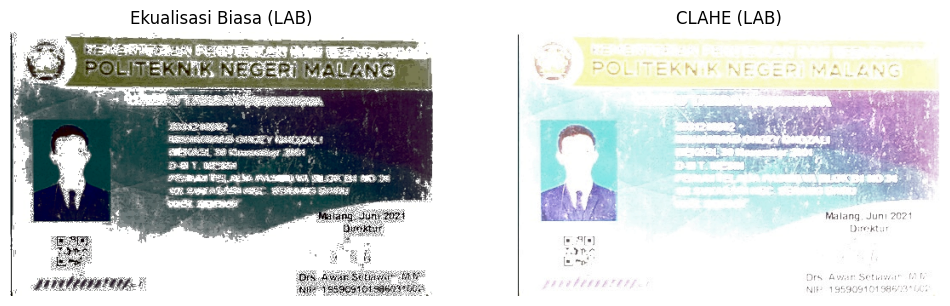

Pergeseran Hue CLAHE: 8.36°
Kecerahan ekualisasi biasa: 146.7
Kecerahan CLAHE: 234.2


In [41]:
# CLAHE pada kanal L (LAB)
lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
l, a, b = cv.split(lab)

clahe = cv.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

l_clahe = clahe.apply(l)
lab_clahe = cv.merge((l_clahe, a, b))
hasil_clahe = cv.cvtColor(lab_clahe, cv.COLOR_LAB2BGR)

# Visualisasi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(he_l, cv.COLOR_BGR2RGB))
plt.title('Ekualisasi Biasa (LAB)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(hasil_clahe, cv.COLOR_BGR2RGB))
plt.title('CLAHE (LAB)')
plt.axis('off')

plt.show()

# Menghitung pergeseran Hue
hue_asli = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)[:, :, 0].astype(float)
hue_clahe = cv.cvtColor(hasil_clahe, cv.COLOR_BGR2HSV)[:, :, 0].astype(float)

selisih_hue = np.abs(hue_asli - hue_clahe)
selisih_hue = np.minimum(selisih_hue, 180 - selisih_hue)
pergeseran_hue = np.mean(selisih_hue) * 2

# Menghitung rata-rata kecerahan
kecerahan_biasa = np.mean(cv.cvtColor(he_l, cv.COLOR_BGR2GRAY))
kecerahan_clahe = np.mean(cv.cvtColor(hasil_clahe, cv.COLOR_BGR2GRAY))

print(f'Pergeseran Hue CLAHE: {pergeseran_hue:.2f}°')
print(f'Kecerahan ekualisasi biasa: {kecerahan_biasa:.1f}')
print(f'Kecerahan CLAHE: {kecerahan_clahe:.1f}')

# PERTANYAAN PRAKTIKUM E2

## 1. Ekualisasi global pada citra KTM Anda

In [42]:
# a. Terapkan ekualisasi manual dan cv.equalizeHist pada KTM1a.jpg versi grayscale.
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra grayscale
berkas = '/content/drive/MyDrive/PCdVK/KTM1a.jpg'
img = cv.imread(berkas, cv.IMREAD_GRAYSCALE)

if img is None:
    print("Gambar tidak ditemukan!")
else:
    print("Ukuran citra:", img.shape)

# Ekualisasi manual
hist, bins = np.histogram(img.flatten(), 256, [0, 256])
cdf = hist.cumsum()

cdf_normalisasi = (cdf - cdf.min()) * 255 / (cdf.max() - cdf.min())
cdf_normalisasi = cdf_normalisasi.astype('uint8')

hasil_manual = cdf_normalisasi[img]

# Ekualisasi menggunakan OpenCV
hasil_cv = cv.equalizeHist(img)

Ukuran citra: (310, 497)


/tmp/ipykernel_1423/832582235.py:10: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img.ravel(), 256, [0, 256])
/tmp/ipykernel_1423/832582235.py:19: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(hasil_manual.ravel(), 256, [0, 256])
/tmp/ipykernel_1423/832582235.py:28: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(hasil_cv.ravel(), 256, [0, 256])


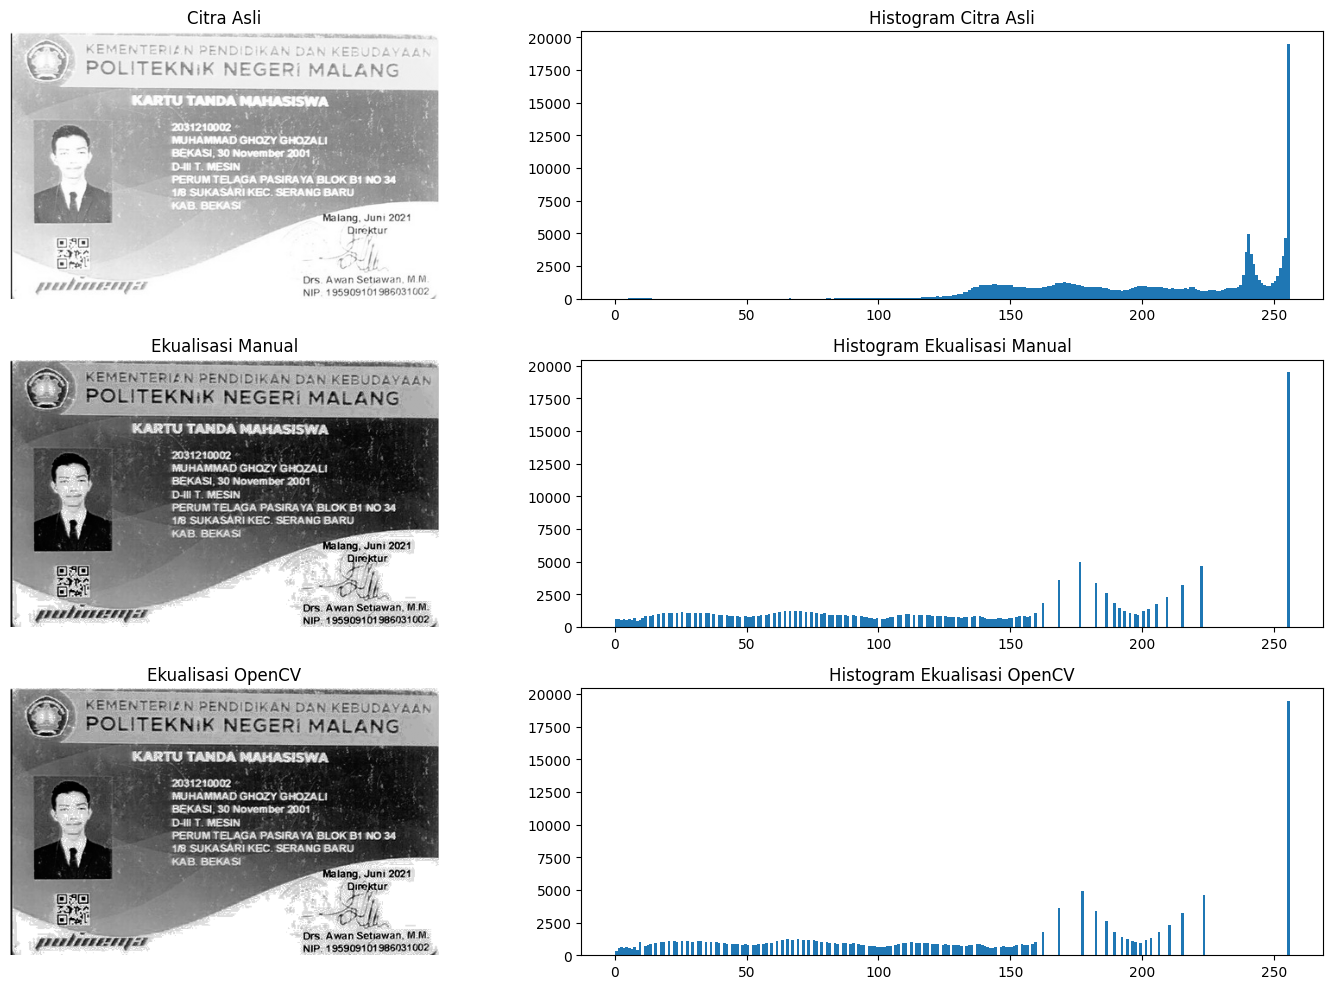

In [43]:
# b. Tampilkan citra asli, citra hasil ekualisasi, serta histogram dalam satu layout.
plt.figure(figsize=(15, 10))

plt.subplot(3, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(3, 2, 2)
plt.hist(img.ravel(), 256, [0, 256])
plt.title('Histogram Citra Asli')

plt.subplot(3, 2, 3)
plt.imshow(hasil_manual, cmap='gray')
plt.title('Ekualisasi Manual')
plt.axis('off')

plt.subplot(3, 2, 4)
plt.hist(hasil_manual.ravel(), 256, [0, 256])
plt.title('Histogram Ekualisasi Manual')

plt.subplot(3, 2, 5)
plt.imshow(hasil_cv, cmap='gray')
plt.title('Ekualisasi OpenCV')
plt.axis('off')

plt.subplot(3, 2, 6)
plt.hist(hasil_cv.ravel(), 256, [0, 256])
plt.title('Histogram Ekualisasi OpenCV')

plt.tight_layout()
plt.show()

In [44]:
# b. Hitung PSNR antara citra asli dan citra hasil ekualisasi. Jelaskan mengapa nilai PSNR justru turun padahal citra terlihat lebih jelas, lalu simpulkan apakah PSNR
# layak dipakai untuk menilai keterbacaan sebuah citra.
psnr_manual = cv.PSNR(img, hasil_manual)
psnr_cv = cv.PSNR(img, hasil_cv)

print(f'PSNR Ekualisasi Manual: {psnr_manual:.2f} dB')
print(f'PSNR Ekualisasi OpenCV: {psnr_cv:.2f} dB')

PSNR Ekualisasi Manual: 9.72 dB
PSNR Ekualisasi OpenCV: 9.77 dB


## 2. Ekualisasi lokal dengan CLAHE pada citra KTM Anda

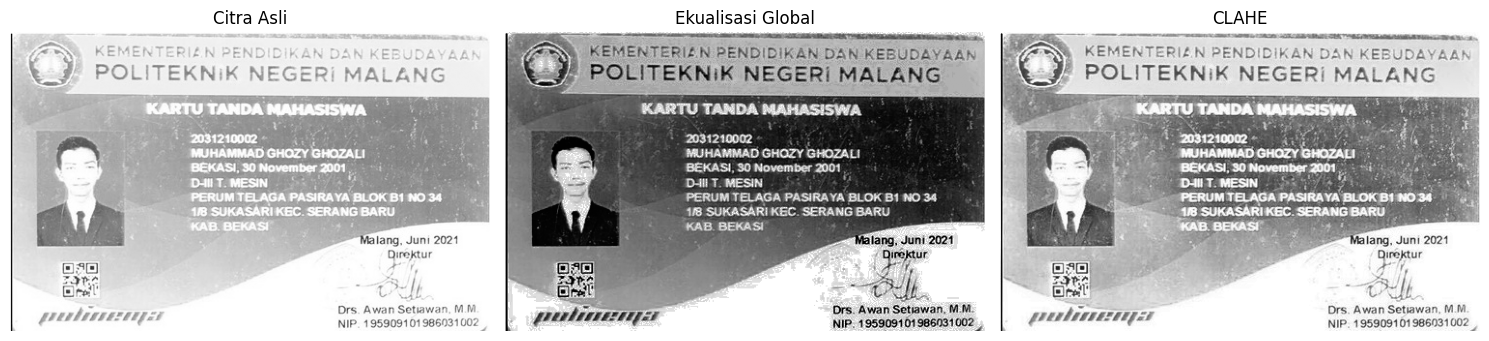

In [48]:
# a. Terapkan CLAHE pada KTM1a.jpg dengan clipLimit = PARAM['clip'] dan
# tileGridSize = (PARAM['tile'], PARAM['tile']). Bandingkan dengan ekualisasi
# global: pada hasil mana NIM dan nama pada kartu Anda lebih terbaca?

# CLAHE
# Menentukan parameter CLAHE
PARAM = {
    'clip': 2.0,
    'tile': 8
}

# Menerapkan CLAHE
clahe = cv.createCLAHE(
    clipLimit=PARAM['clip'],
    tileGridSize=(PARAM['tile'], PARAM['tile'])
)

hasil_clahe = clahe.apply(img)

# Perbandingan
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(hasil_cv, cmap='gray')
plt.title('Ekualisasi Global')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_clahe, cmap='gray')
plt.title('CLAHE')
plt.axis('off')

plt.tight_layout()
plt.show()

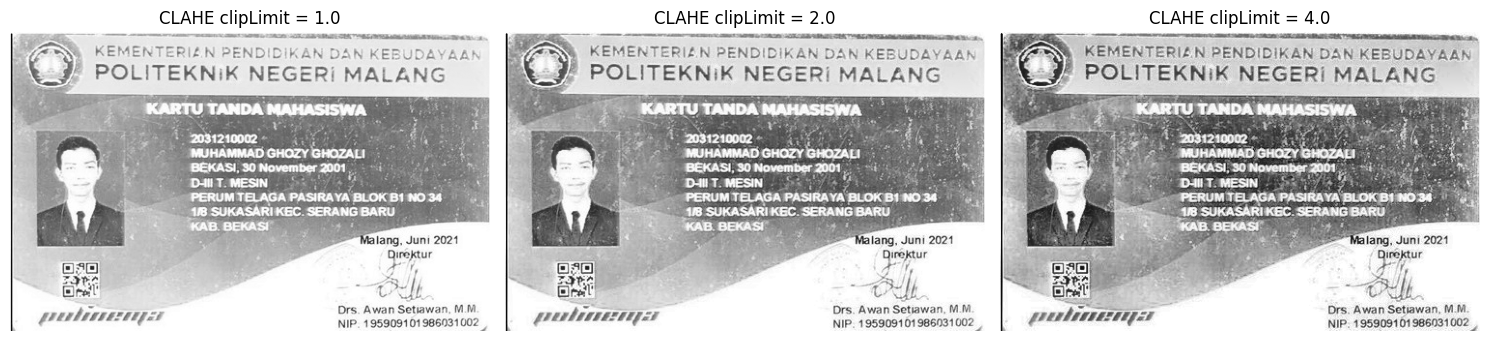

In [49]:
# b. Mencoba tiga nilai clipLimit lain

nilai_clip = [1.0, 2.0, 4.0]

plt.figure(figsize=(15, 5))

for i, clip in enumerate(nilai_clip):
    clahe = cv.createCLAHE(
        clipLimit=clip,
        tileGridSize=(PARAM['tile'], PARAM['tile'])
    )

    hasil = clahe.apply(img)

    plt.subplot(1, 3, i+1)
    plt.imshow(hasil, cmap='gray')
    plt.title(f'CLAHE clipLimit = {clip}')
    plt.axis('off')

plt.tight_layout()
plt.show()

# E-3 TUGAS PRAKTIKUM DITHERING

# 1

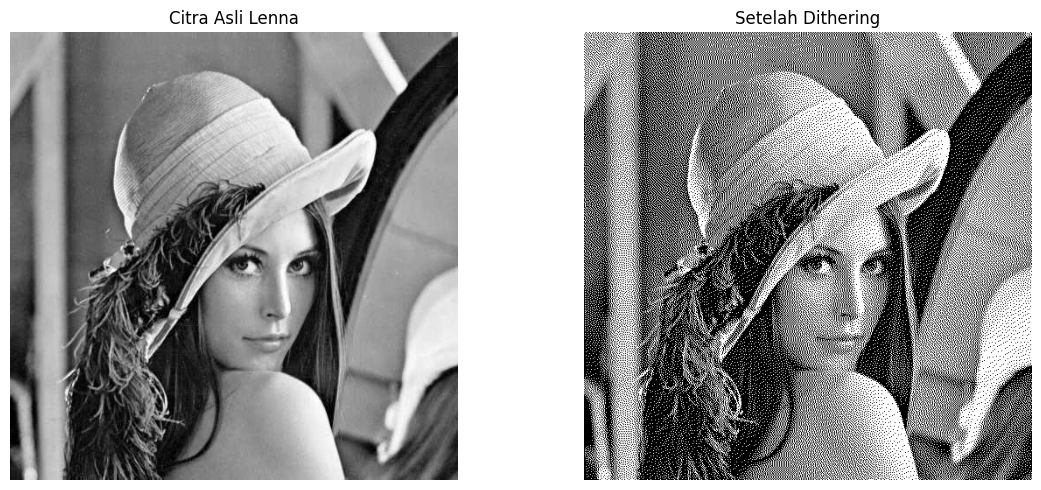

In [52]:
def floyd_steinberg(gray, L=2):
    img = gray.astype(np.float32).copy()

    step = 255.0 / (L - 1)

    H, W = img.shape

    for y in range(H):
        for x in range(W):

            lama = img[y, x]

            baru = np.round(lama / step) * step

            img[y, x] = baru

            error = lama - baru

            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16

            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16

            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16

            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

    return np.clip(img, 0, 255).astype(np.uint8)


# Membaca Lenna sebagai grayscale
lenna = cv.imread(
    '/content/drive/MyDrive/PCdVK/lenna.jpg',
    cv.IMREAD_GRAYSCALE
)

# Floyd-Steinberg 2 level
lenna_dither = floyd_steinberg(lenna, L=2)

# Tampilkan sebelum dan sesudah
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(lenna, cmap='gray')
plt.title('Citra Asli Lenna')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lenna_dither, cmap='gray')
plt.title('Setelah Dithering')
plt.axis('off')

plt.tight_layout()
plt.show()

# 2

Ukuran citra: (310, 497)


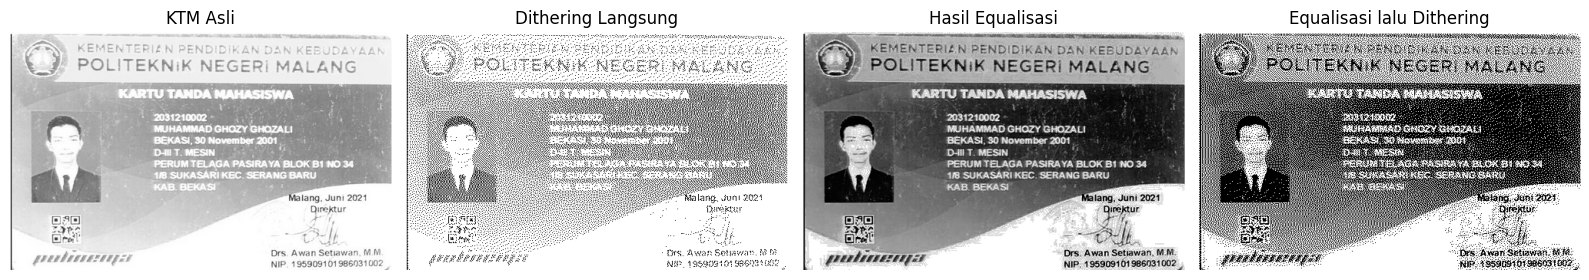

In [54]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Fungsi Histogram Equalization manual
def histogram_manual(img):
    hist = np.zeros(256, dtype=int)

    tinggi, lebar = img.shape

    for y in range(tinggi):
        for x in range(lebar):
            nilai = img[y, x]
            hist[nilai] += 1

    return hist


# Fungsi Floyd-Steinberg
def floyd_steinberg(gray, L=2):
    img = gray.astype(np.float32).copy()

    step = 255.0 / (L - 1)

    H, W = img.shape

    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            baru = np.round(lama / step) * step

            img[y, x] = baru
            error = lama - baru

            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16

            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16

            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16

            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

    return np.clip(img, 0, 255).astype(np.uint8)


# Parameter dithering
PARAM = {'L': 2}


# Membaca KTM sebagai grayscale
ktm = cv.imread(
    '/content/drive/MyDrive/PCdVK/KTM1a.jpg',
    cv.IMREAD_GRAYSCALE
)

if ktm is None:
    print("Gambar tidak ditemukan. Periksa lokasi dan nama file!")

else:
    print("Ukuran citra:", ktm.shape)

    # Histogram Equalization manual
    hist_ktm = histogram_manual(ktm)

    prob_ktm = hist_ktm / ktm.size
    cdf_ktm = np.cumsum(prob_ktm)

    L = 256
    transform_ktm = np.round(
        (L - 1) * cdf_ktm
    ).astype(np.uint8)

    ktm_equalized = transform_ktm[ktm]

    # Dithering langsung
    ktm_dither_langsung = floyd_steinberg(
        ktm,
        L=PARAM['L']
    )

    # Dithering setelah equalization
    ktm_equalized_dither = floyd_steinberg(
        ktm_equalized,
        L=PARAM['L']
    )

    # Menampilkan hasil
    plt.figure(figsize=(16, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(ktm, cmap='gray')
    plt.title('KTM Asli')
    plt.axis('off')

    plt.subplot(1, 4, 2)
    plt.imshow(ktm_dither_langsung, cmap='gray')
    plt.title('Dithering Langsung')
    plt.axis('off')

    plt.subplot(1, 4, 3)
    plt.imshow(ktm_equalized, cmap='gray')
    plt.title('Hasil Equalisasi')
    plt.axis('off')

    plt.subplot(1, 4, 4)
    plt.imshow(ktm_equalized_dither, cmap='gray')
    plt.title('Equalisasi lalu Dithering')
    plt.axis('off')

    plt.tight_layout()
    plt.show()